In [267]:
# Author: Till Zemann
# License: MIT License
import sys
sys.path.append("..")
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
from net.dale_util import RL_Hidden_Buffer

1.12.0


In [268]:
buffer = RL_Hidden_Buffer(10000)
simple_type = 'rnn'
ei_type = 'eisep'
configuration = 'eisep_actor'
actor_lr = 0.001
critic_lr = 0.005

info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'

buffer_path = info_path.replace('.pkl', '_buffer0.pkl')
buffer.load(buffer_path)
print(buffer.state.shape)
print(buffer.ptr, buffer.n_h)

./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/eisep_actor_buffer0.pkl size: 9683
(12000, 8)
9683 2


In [269]:
print(buffer.state[200])
### Meaning:
# lander x coordinate
# lander y coordinate
# lander x velocity
# lander y velocity
# lander angle
# lander angular velocity
# left leg contact
# right leg contact
print(buffer.action[0], buffer.action.max())
### Meaning:
# do nothing
# fire left engine
# fire main engine
# fire right engine
print(buffer.hidden_state[0].shape)
print(buffer.reward[0], buffer.done[0])
network_name = 'actor'


[ 0.19333363  1.52767324  0.15889622 -0.05712537  0.09901831  0.08159838
  0.          0.        ]
[2.] 3.0
(2, 64)
[-2.57228624] [0.]


(9683, 4)
(9683, 12)
(9683, 64)
x: min -0.32, max 1.00,           mean 0.34, std 0.28
y: min 0.08, max 1.65,           mean 1.18, std 0.35
vx: min -0.74, max 0.76,           mean 0.15, std 0.15
vy: min -0.57, max 0.43,           mean -0.04, std 0.10
a: min -0.47, max 0.53,           mean 0.00, std 0.13
va: min -0.48, max 0.53,           mean 0.00, std 0.14


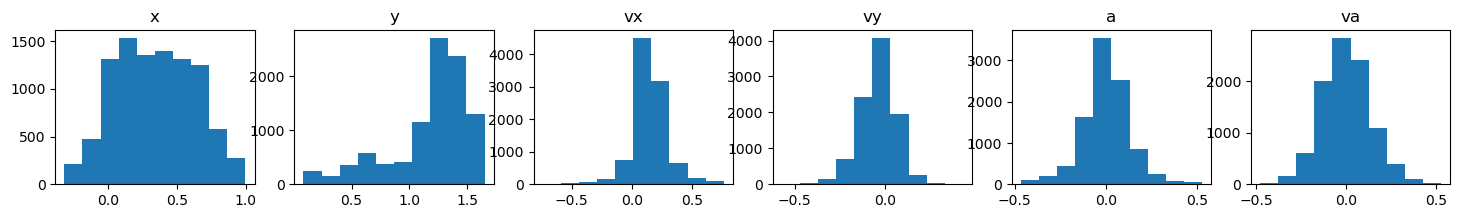

In [ ]:
n_action = int(buffer.action.max()+1)
feature_dim = buffer.state.shape[-1] + n_action
buffer_state = buffer.state[:buffer.ptr]
buffer_action = buffer.action[:buffer.ptr]
buffer_done = buffer.done[:buffer.ptr]
buffer_action_onehot = np.eye(n_action)[buffer_action.astype(np.int64).squeeze(-1)]
print(buffer_action_onehot.shape)
features = np.concatenate([buffer_state, buffer_action_onehot], axis=-1)
print(features.shape)
if network_name == 'critic':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 0]
elif network_name == 'actor':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 1]
print(buffer_hidden.shape)
### up is positive y velocity
fig, ax = plt.subplots(1,6, figsize=(18,2))
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
for i in range(6):
    ax[i].hist(buffer_state[:,i])
    print(f'{tick_names[i]}: min {buffer_state[:,i].min():.2f}, max {buffer_state[:,i].max():.2f}, \
          mean {buffer_state[:,i].mean():.2f}, std {buffer_state[:,i].std():.2f}')
    ax[i].set_title(tick_names[i])
plt.show()

R^2: 0.9453144963992139
Coefficients: [[ 8.77284479e-02  7.93815099e-03 -1.87919853e-01  3.83634323e-01
  -2.17277990e-01 -4.61374407e-01  3.46567087e-01  2.62653158e-01]
 [ 9.33851518e-02 -1.16513169e-01 -5.90937129e-01  1.12101774e-01
   1.06207725e+00  1.49618686e-01 -1.50925034e-01 -7.52445287e-02]
 [ 1.98543509e-01  1.53246357e-01 -3.27373976e-01  2.85417305e-01
   5.11851323e-01 -2.42531034e-02  5.50064417e-02 -1.95105438e-02]
 [-1.69126877e-02 -2.87997728e-01 -2.07096932e-01  1.71160312e-01
   3.51602050e-01  1.66944288e-01  1.82849309e-01  1.83065615e-01]
 [ 1.02850634e-02 -3.65618303e-02 -1.93235254e-01 -1.96980743e-01
   9.78992625e-01  2.19347574e-01 -2.04780216e-01 -7.16996863e-02]
 [-2.79614502e-02  1.84750177e-02 -9.03044502e-02  1.40087091e-01
   6.57807183e-01  1.38794022e-02 -1.55754909e-01  6.19097363e-02]
 [ 2.81052110e-01 -4.60023735e-02 -2.53704442e-01  2.86277631e-01
  -1.59675840e-01 -3.97424828e-01  3.74110200e-01  5.62725078e-02]
 [ 1.01524942e-01 -3.35596388e-

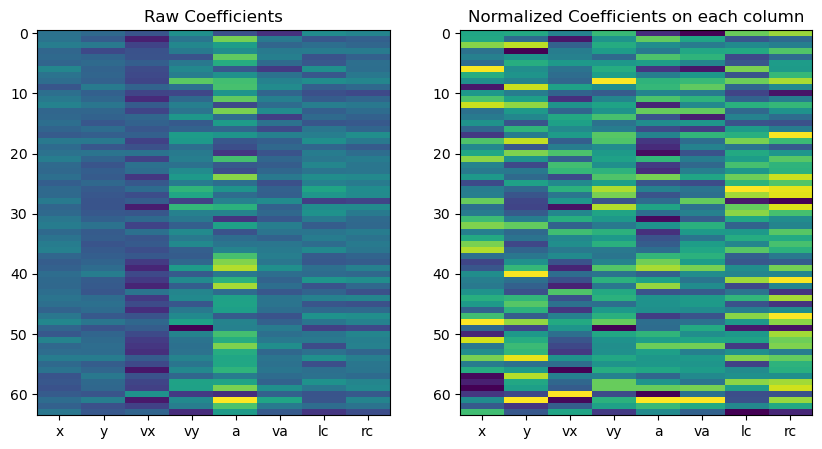

In [271]:
from sklearn.linear_model import LinearRegression
from matplotlib import pyplot as plt
reg = LinearRegression().fit(buffer_state, buffer_hidden)
print('R^2:', reg.score(buffer_state, buffer_hidden))
print('Coefficients:', reg.coef_)
normalized_coefficients = (reg.coef_ - np.min(reg.coef_, axis=0))/(np.max(reg.coef_, axis=0) - np.min(reg.coef_, axis=0)+1e-10)
print('Intercept:', reg.intercept_)
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
fig, ax = plt.subplots(1,2,figsize=(10,5))
ax[0].imshow(reg.coef_, aspect='auto')
ax[0].set_title('Raw Coefficients')
ax[0].set_xticks(np.arange(len(tick_names)))
ax[0].set_xticklabels(tick_names)
ax[1].imshow(normalized_coefficients, aspect='auto')
ax[1].set_title('Normalized Coefficients on each column')
ax[1].set_xticks(np.arange(len(tick_names)))

ax[1].set_xticklabels(tick_names)
plt.show()


[0 0 0 ... 0 0 0]
(4, 64)


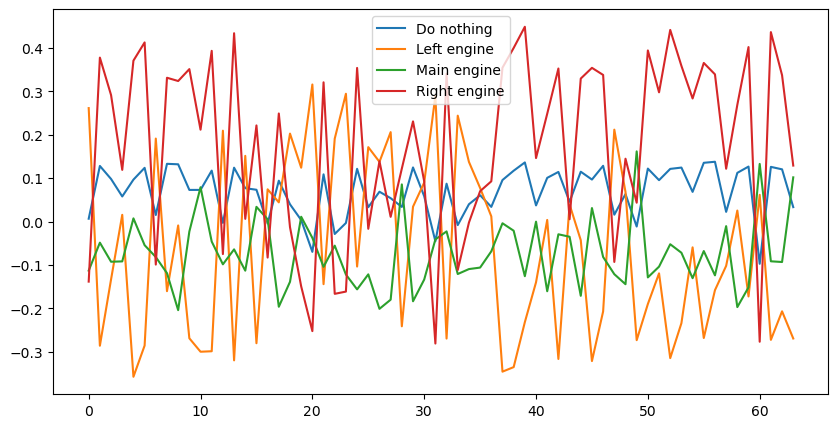

In [272]:
action_specific_idxs = [np.where(buffer_action.squeeze(-1)==i,1,0) for i in range(n_action)]
print(action_specific_idxs[0])
def action_specific_selectivity(i):
    idxs = action_specific_idxs[i]
    positive_hidden = buffer_hidden[idxs==1]
    negative_hidden = buffer_hidden[idxs==0]
    selectivity = (positive_hidden.mean(axis=0) - negative_hidden.mean(axis=0)) / (positive_hidden.std(axis=0) + negative_hidden.std(axis=0) + 1e-6)
    return selectivity
action_selectivities = [action_specific_selectivity(i) for i in range(n_action)]
action_selectivity_matrix = np.stack(action_selectivities, axis=0)
print(action_selectivity_matrix.shape)
fig, ax = plt.subplots(1,1,figsize=(10,5))
action_names = ['Do nothing', 'Left engine', 'Main engine', 'Right engine']
for i in range(n_action):
    ax.plot(action_selectivities[i], label=action_names[i])
ax.legend()
plt.show()

In [273]:
info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
with open(info_path, 'rb') as f:
    info = pkl.load(f)
net_state_dicts = info['net_state_dict']
obs_dim = buffer_state.shape[-1]
action_dim = n_action
device = 'cpu'
n_envs = 1
hidden_size = buffer_hidden.shape[-1]
seed = 1
agent = A2C(obs_dim, action_dim, device, critic_lr, actor_lr, n_envs, hidden_size,
            configuration, simple_type=simple_type, ei_type=ei_type)
agent.load_state_dict(net_state_dicts[seed])
agent.eval()

Using <class 'net.rnncell_variant.SimpleRNNCell'> for critic and <class 'net.rnncell_variant.EIRNNCell'> for actor


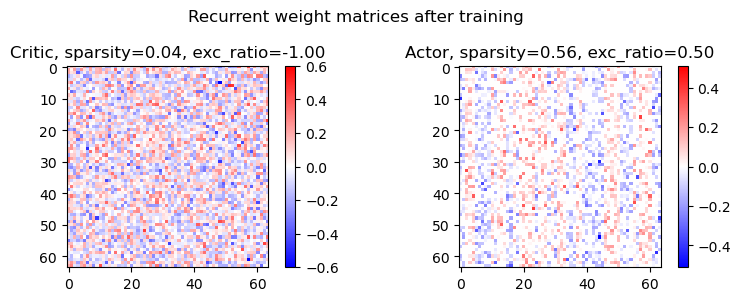

In [274]:
def score(weight, module):
    sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
    exc_ratio = -1
    if hasattr(module, 'get_ei_entropy_loss'):
        eimask_logit = module.eimask_logit.detach().cpu().numpy()
        exc_ratio = np.mean(eimask_logit[:,0]>eimask_logit[:,1])
    return sparsity, exc_ratio

W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8, 3))
axs[0].set_title(f"Critic, sparsity={sparsity_critic:.2f}, exc_ratio={exc_ratio_critic:.2f}")
limit = np.max(np.abs(W_critic))
im0 = axs[0].imshow(W_critic, vmin=-limit, vmax=limit, cmap='bwr')
plt.colorbar(im0, ax=axs[0])
axs[1].set_title(f"Actor, sparsity={sparsity_actor:.2f}, exc_ratio={exc_ratio_actor:.2f}")
limit = np.max(np.abs(W_actor))
im1 = axs[1].imshow(W_actor, vmin=-limit, vmax=limit, cmap='bwr')
plt.colorbar(im1, ax=axs[1])
plt.suptitle("Recurrent weight matrices after training")
plt.tight_layout()
plt.show()

In [275]:
if network_name == 'actor':
    W = W_actor
elif network_name == 'critic':
    W = W_critic


0.1474616005179251
(64,)
[ 0 13  1 35  0 15]


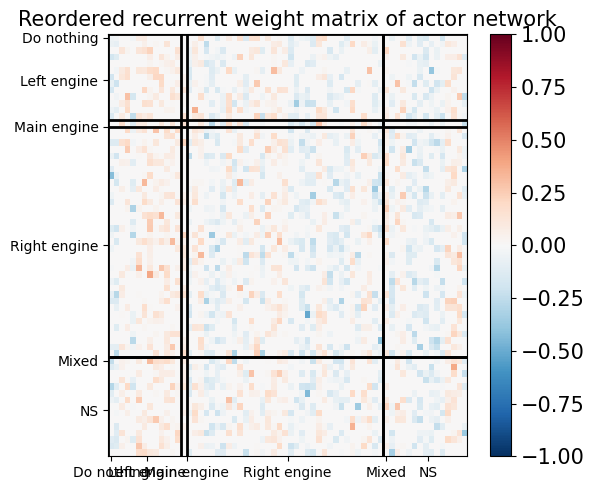

In [276]:
threshold = np.std(action_selectivity_matrix)*0.8
print(threshold)
past_threshold = np.where(action_selectivity_matrix>threshold, 1, 0).sum(0)
max_action = np.argmax(action_selectivity_matrix, 0)
print(max_action.shape)
non_selective_mask = (past_threshold==0)
mixed_selective_mask = (past_threshold>1)
non_selective_neurons = np.where(non_selective_mask)[0]

# other_choice_neurons = np.unique(np.concatenate([action_selective_neurons[i] for i in range(n_action) if i != 2]))
mixed_selective_neurons = np.where(mixed_selective_mask)[0]
action_selective_neurons = [np.where((max_action==i)&(~non_selective_mask)&(~mixed_selective_mask))[0] for i in range(n_action)]
action_neurons = action_selective_neurons + [mixed_selective_neurons, non_selective_neurons]
action_perm = np.concatenate(action_neurons)
n_neurons = np.array([len(x) for x in action_neurons])
# action_selective_neurons = [np.where((action_selectivities[i])>threshold)[0] for i in range(n_action)]
# main_engine_neurons = action_selective_neurons[2]

# main_engine_neurons = np.setdiff1d(main_engine_neurons, np.concatenate([mixed_selective_neurons, non_selective_neurons]))
# other_choice_neurons = np.setdiff1d(other_choice_neurons, np.concatenate([mixed_selective_neurons, non_selective_neurons]))


N = W.shape[0]
all_neurons = np.arange(N)
# action_neurons = [main_engine_neurons, other_choice_neurons, mixed_selective_neurons, non_selective_neurons]
# action_perm = np.concatenate([main_engine_neurons, other_choice_neurons, mixed_selective_neurons, non_selective_neurons])
reordered_weight = W[np.ix_(action_perm, action_perm)]
fig, ax = plt.subplots(1,1,figsize=(6,5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=15)
# n_neurons = np.array([len(main_engine_neurons), len(other_choice_neurons), len(mixed_selective_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(n_neurons)
for boundary in phase_boundaries[:-1]:
    plt.axhline(boundary-0.5, color='k', linewidth=2)
    plt.axvline(boundary-0.5, color='k', linewidth=2)
print(n_neurons)
action_related_names = action_names+['Mixed', 'NS']
plt.xticks(phase_boundaries-n_neurons/2, action_related_names)
plt.yticks(phase_boundaries-n_neurons/2, action_related_names)
plt.title(f'Reordered recurrent weight matrix of {network_name} network', fontsize=15)
plt.tight_layout()
plt.show()

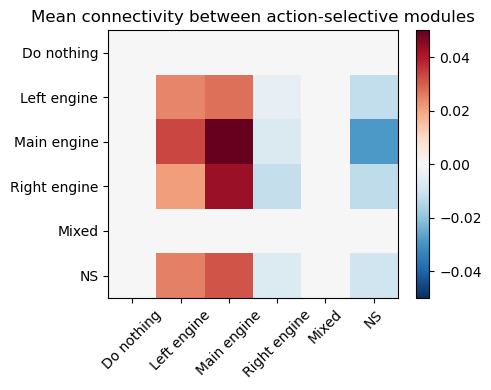

In [277]:
# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = action_neurons
n_groups = len(groups)

W_group = np.zeros((n_groups, n_groups))

for p in range(n_groups):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        rows = groups[p]
        cols = groups[q]
        if len(rows) == 0 or len(cols) == 0:
            W_group[p, q] = 0.0
        else:
            sub = W[np.ix_(rows, cols)]
            W_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,4))
im = ax.imshow(W_group, cmap='RdBu_r', vmin=-0.05, vmax=0.05, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(n_groups))
ax.set_xticklabels(action_related_names, rotation=45)
ax.set_yticklabels(action_related_names)
ax.set_title('Mean connectivity between action-selective modules')
plt.tight_layout()
plt.show()


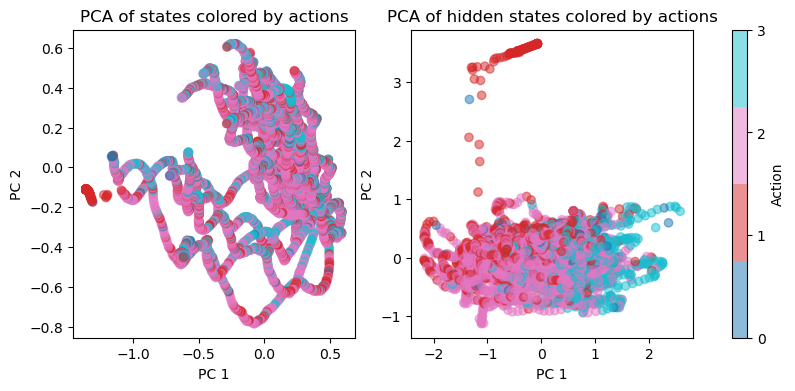

/tmp/ipykernel_2571/3966338742.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[action].scatter(state_pca[action_idx,0], state_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))


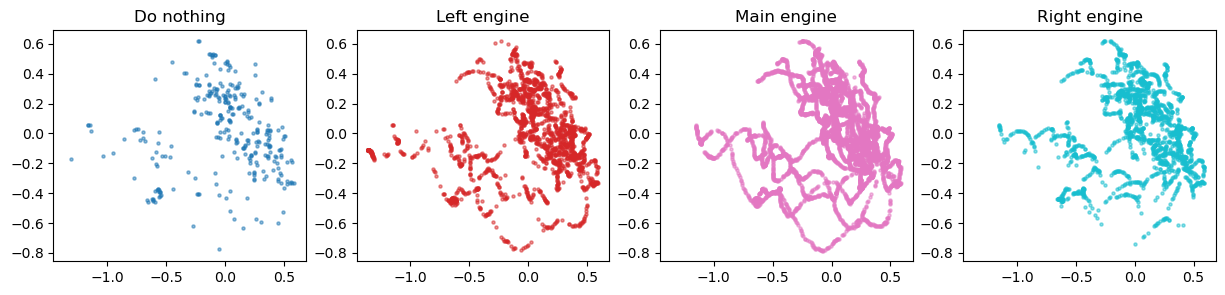

/tmp/ipykernel_2571/3966338742.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[action].scatter(hidden_pca[action_idx,0], hidden_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))


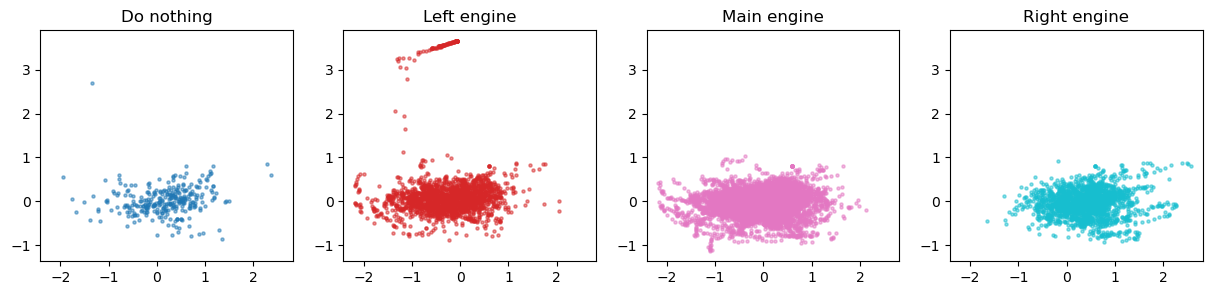

In [278]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
state_pca = pca.fit_transform(buffer_state)
fig, ax = plt.subplots(1,2,figsize=(10,4))
colormap = plt.get_cmap('tab10', n_action)
ax[0].scatter(state_pca[:,0], state_pca[:,1], c=buffer_action.squeeze(-1).astype(np.int64), cmap=colormap, alpha=0.5)
ax[0].set_xlabel('PC 1')
ax[0].set_ylabel('PC 2')
ax[0].set_title('PCA of states colored by actions')
ax0_lim = (ax[0].get_xlim(), ax[0].get_ylim())
pca = PCA(n_components=2)
hidden_pca = pca.fit_transform(buffer_hidden)
s = ax[1].scatter(hidden_pca[:,0], hidden_pca[:,1], c=buffer_action.squeeze(-1).astype(np.int64), cmap=colormap, alpha=0.5)
ax[1].set_xlabel('PC 1')
ax[1].set_ylabel('PC 2')
ax[1].set_title('PCA of hidden states colored by actions')
ax1_lim = (ax[1].get_xlim(), ax[1].get_ylim())
# fig.colorbar(label='Action', ticks=np.arange(n_action), ax=ax[1], cax=ax[1], mappable=s)
plt.colorbar(s, ax=ax, label='Action', ticks=np.arange(n_action))
# plt.tight_layout()
plt.show()
action_names = ['Do nothing', 'Left engine', 'Main engine', 'Right engine']
fig, ax = plt.subplots(1,4, figsize=(15,3))
for action in range(n_action):
    action_idx = np.where(buffer_action.squeeze(-1).astype(np.int64)==action)[0]
    ax[action].scatter(state_pca[action_idx,0], state_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))
    ax[action].set_title(action_names[action])
    ax[action].set_xlim(ax0_lim[0])
    ax[action].set_ylim(ax0_lim[1])
plt.show()
fig, ax = plt.subplots(1,4, figsize=(15,3))
for action in range(n_action):
    action_idx = np.where(buffer_action.squeeze(-1).astype(np.int64)==action)[0]
    ax[action].scatter(hidden_pca[action_idx,0], hidden_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))
    ax[action].set_title(action_names[action])
    ax[action].set_xlim(ax1_lim[0])
    ax[action].set_ylim(ax1_lim[1])
plt.show()

In [279]:
from rl.phase_detect import tag_lunar_lander_phases_batch_2

In [280]:
buffer_phase = tag_lunar_lander_phases_batch_2(
    buffer_state,
    buffer_action,
    buffer_done
)

print(buffer_phase.shape)  # (L,)
print(buffer_phase[:500])
print(np.bincount(buffer_phase))  # count each phase
np.save('buffer_phase.npy', buffer_phase)

(9683,)
[1 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 1 0 1 0 0 0 1 0
 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1 0 1
 1 1 0 0 0 0 0 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 0 1 0 2 0 2 2 1 1 1 2 0 1 1
 0 1 0 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 1 1 1 1 0 0 1 1 0 1 1 0 0 0 1 1
 1 1 1 0 1 1 0 1 1 1 0 0 1 1 1 1 0 0 0 1 1 0 1 0 1 0 0 1 1 0 0 1 1 0 1 1 1
 1 0 0 1 1 0 1 0 1 0 0 2 2 2 0 1 0 0 1 1 1 0 1 1 1 0 1 0 0 1 0 1 1 1 1 1 1
 1 1 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 1 1 1 0 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 1 1 1 1 0 1 0 0 1 1 1 0 0 0 1 1 0 2 2 0 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 1 1 0 0 0 0 1 1 1 1 1 1 0
 1 1 1 0 0 0 0 1 1 0 0 0 1 1 1 1 0 0 1 1 1 0 0 2 2 0 2 2 2 2 0 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 0 1 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1 1
 1 0 2 1 1 0 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0
 1 0 1 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 1 0 0 1 1 1 0 1 0 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 

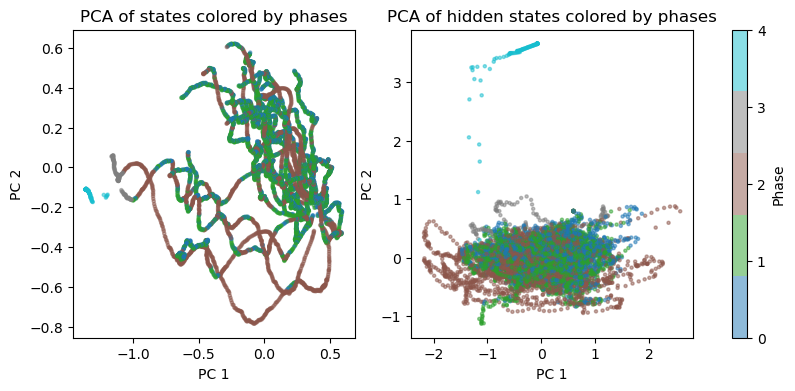

/tmp/ipykernel_2571/2642791460.py:27: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[phase].scatter(state_pca[phase_idx,0], state_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))


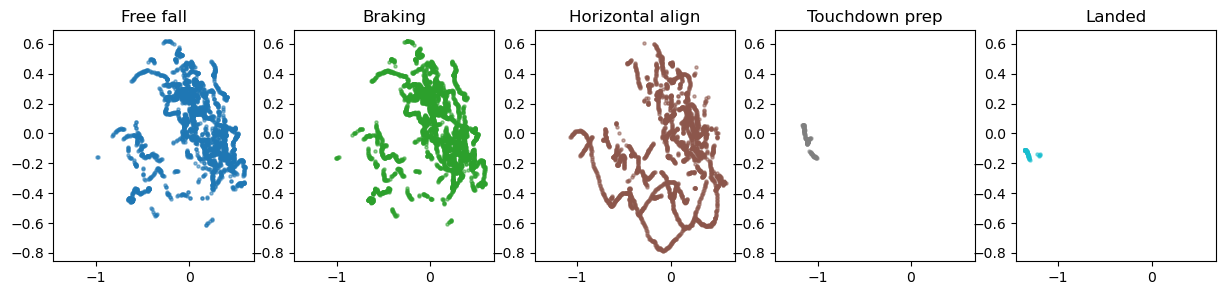

/tmp/ipykernel_2571/2642791460.py:35: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[phase].scatter(hidden_pca[phase_idx,0], hidden_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))


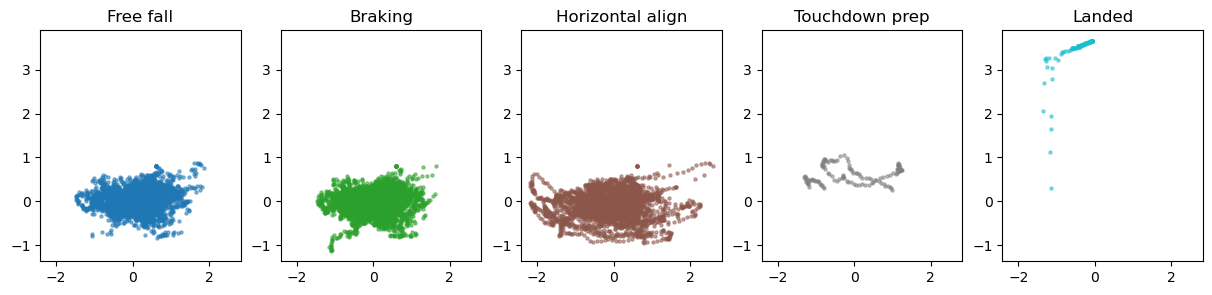

In [281]:
from sklearn.decomposition import PCA
n_phase = 5
pca = PCA(n_components=2)
state_pca = pca.fit_transform(buffer_state)
fig, ax = plt.subplots(1,2,figsize=(10,4))
colormap = plt.get_cmap('tab10', n_phase)
ax[0].scatter(state_pca[:,0], state_pca[:,1], c=buffer_phase, cmap=colormap, alpha=0.5, s=5)
ax[0].set_xlabel('PC 1')
ax[0].set_ylabel('PC 2')
ax[0].set_title('PCA of states colored by phases')
ax0_lim = (ax[0].get_xlim(), ax[0].get_ylim())
pca = PCA(n_components=2)
hidden_pca = pca.fit_transform(buffer_hidden)
s = ax[1].scatter(hidden_pca[:,0], hidden_pca[:,1], c=buffer_phase, cmap=colormap, alpha=0.5, s=5)
ax[1].set_xlabel('PC 1')
ax[1].set_ylabel('PC 2')
ax[1].set_title('PCA of hidden states colored by phases')
ax1_lim = (ax[1].get_xlim(), ax[1].get_ylim())
# fig.colorbar(label='Action', ticks=np.arange(n_action), ax=ax[1], cax=ax[1], mappable=s)
plt.colorbar(s, ax=ax, label='Phase', ticks=np.arange(n_phase))
# plt.tight_layout()
plt.show()
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed', 'Crash']
fig, ax = plt.subplots(1,5, figsize=(15,3))
for phase in range(n_phase):
    phase_idx = np.where(buffer_phase==phase)[0]
    ax[phase].scatter(state_pca[phase_idx,0], state_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))
    ax[phase].set_title(phase_names[phase])
    ax[phase].set_xlim(ax0_lim[0])
    ax[phase].set_ylim(ax0_lim[1])
plt.show()
fig, ax = plt.subplots(1,5, figsize=(15,3))
for phase in range(n_phase):
    phase_idx = np.where(buffer_phase==phase)[0]
    ax[phase].scatter(hidden_pca[phase_idx,0], hidden_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))
    ax[phase].set_title(phase_names[phase])
    ax[phase].set_xlim(ax1_lim[0])
    ax[phase].set_ylim(ax1_lim[1])
plt.show()

[0 0 1 ... 0 0 0]


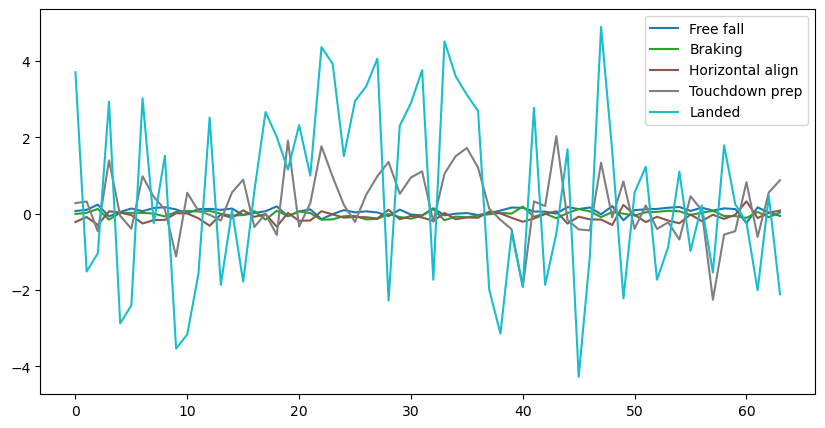

In [282]:
phase_specific_idxs = [np.where(buffer_phase==i,1,0) for i in range(n_phase)]
print(phase_specific_idxs[0])
def specific_selectivity(i):
    idxs = phase_specific_idxs[i]
    positive_hidden = buffer_hidden[idxs==1]
    negative_hidden = buffer_hidden[idxs==0]
    selectivity = (positive_hidden.mean(axis=0) - negative_hidden.mean(axis=0)) / (positive_hidden.std(axis=0) + negative_hidden.std(axis=0) + 1e-6)
    return selectivity
phase_selectivities = [specific_selectivity(i) for i in range(n_phase)]
fig, ax = plt.subplots(1,1,figsize=(10,5))
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed']
colors = plt.get_cmap('tab10', n_phase)
for i in range(len(phase_names)):
    ax.plot(phase_selectivities[i], label=phase_names[i], color=colors(i))
ax.legend()
plt.show()


In [283]:
# selectivities: list length n_phase, each [hidden_size]
phase_selectivity_matrix = np.stack(phase_selectivities, axis=0)  # shape [n_phase, N]
n_phase, N = phase_selectivity_matrix.shape
print(np.nanstd(phase_selectivity_matrix))
thr = np.nanstd(phase_selectivity_matrix)*0.8 # same as before, or adjust
past_threshold = (phase_selectivity_matrix > thr).sum(0)
mixed_mask = (past_threshold>1)
mixed_neurons = np.where(mixed_mask)[0]
non_selective_mask = (past_threshold==0)
non_selective_neurons = np.where(non_selective_mask)[0]
max_phase = np.argmax(phase_selectivity_matrix, axis=0)


# # Absolute selectivity for grouping
# abs_sel = np.abs(phase_selectivity_matrix)           # [n_phase, N]
# max_phase = np.argmax(abs_sel, axis=0)    # [N], 0..n_phase-1
# max_val   = np.max(abs_sel, axis=0)       # [N]

# # Non-selective: no phase with |sel|>thr
# non_selective_mask = max_val <= thr
# non_selective_neurons = np.where(non_selective_mask)[0]

# Phase-specific neurons: prefer one phase & pass threshold
phase_neurons = [np.where((max_phase==i) & (~mixed_mask) & (~non_selective_mask))[0] for i in range(n_phase)]

# Mixed-selective: strong for >1 phase (optional)
# strong_mask = abs_sel > thr              # [n_phase, N]
# n_strong = strong_mask.sum(axis=0)       # how many phases each neuron is strongly tuned to
# mixed_mask = n_strong > 1
# mixed_selective_neurons = np.where(mixed_mask & (~non_selective_mask))[0]

# Final permutation

phase_perm = np.concatenate(phase_neurons + [mixed_neurons] + [non_selective_neurons])
assert len(phase_perm) == N


1.1409205367043913


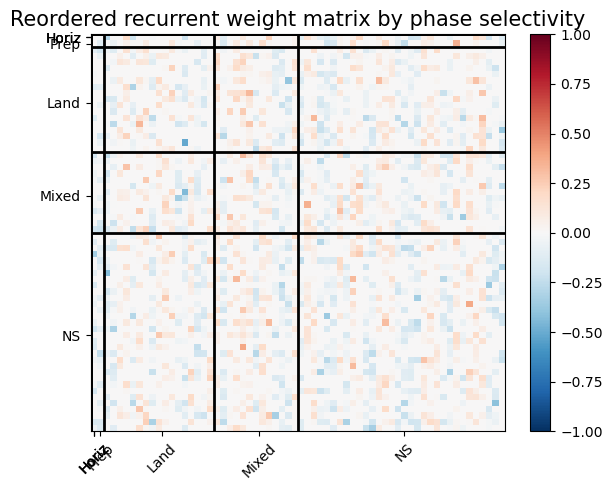

In [284]:
reordered_weight = W[np.ix_(phase_perm, phase_perm)]

fig, ax = plt.subplots(1,1,figsize=(6,5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=10)

# Block boundaries
phase_group_sizes = np.array([len(g) for g in phase_neurons] + [len(mixed_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(phase_group_sizes)

for b in phase_boundaries[:-1]:
    plt.axhline(b - 0.5, color='k', linewidth=2)
    plt.axvline(b - 0.5, color='k', linewidth=2)

centers = phase_boundaries - phase_group_sizes / 2

phase_names = ['Free', 'Brake', 'Horiz', 'Prep', 'Land']
xtick_labels = phase_names + ['Mixed', 'NS']
plt.xticks(centers, xtick_labels, rotation=45)
plt.yticks(centers, xtick_labels)

plt.title('Reordered recurrent weight matrix by phase selectivity', fontsize=15)
plt.tight_layout()
plt.show()


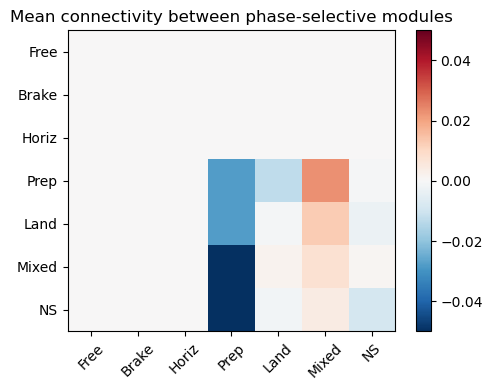

In [285]:
# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = phase_neurons + [mixed_neurons, non_selective_neurons]
n_groups = len(groups)

W_group = np.zeros((n_groups, n_groups))

for p in range(n_groups):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        rows = groups[p]
        cols = groups[q]
        if len(rows) == 0 or len(cols) == 0:
            W_group[p, q] = 0.0
        else:
            sub = W[np.ix_(rows, cols)]
            W_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,4))
im = ax.imshow(W_group, cmap='RdBu_r', vmin=-0.05, vmax=0.05, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(n_groups))
ax.set_xticklabels(xtick_labels, rotation=45)
ax.set_yticklabels(xtick_labels)
ax.set_title('Mean connectivity between phase-selective modules')
plt.tight_layout()
plt.show()


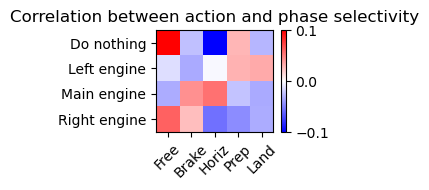

In [286]:
correlation_matrix = action_selectivity_matrix @ phase_selectivity_matrix.T  # [n_action, n_phase]
correlation_matrix = np.where(np.isnan(correlation_matrix), 0, correlation_matrix)
column_norm = np.linalg.norm(correlation_matrix, axis=1, keepdims=True)
row_norm = np.linalg.norm(correlation_matrix, axis=0, keepdims=True)
correlation_matrix_normalized = correlation_matrix/column_norm/row_norm
fig, ax = plt.subplots(1,1,figsize=(3,2))
cbar = ax.imshow(correlation_matrix_normalized, cmap='bwr', aspect='auto', vmin=-0.1, vmax=0.1)
plt.colorbar(cbar, ax=ax)
ax.set_xticks(np.arange(n_phase))
ax.set_yticks(np.arange(n_action))
ax.set_xticklabels(phase_names, rotation=45)
ax.set_yticklabels(action_names)
plt.title('Correlation between action and phase selectivity')
plt.tight_layout()
plt.show()

R^2: 0.9453144963992139
Coefficients: (64, 8)
(64,)


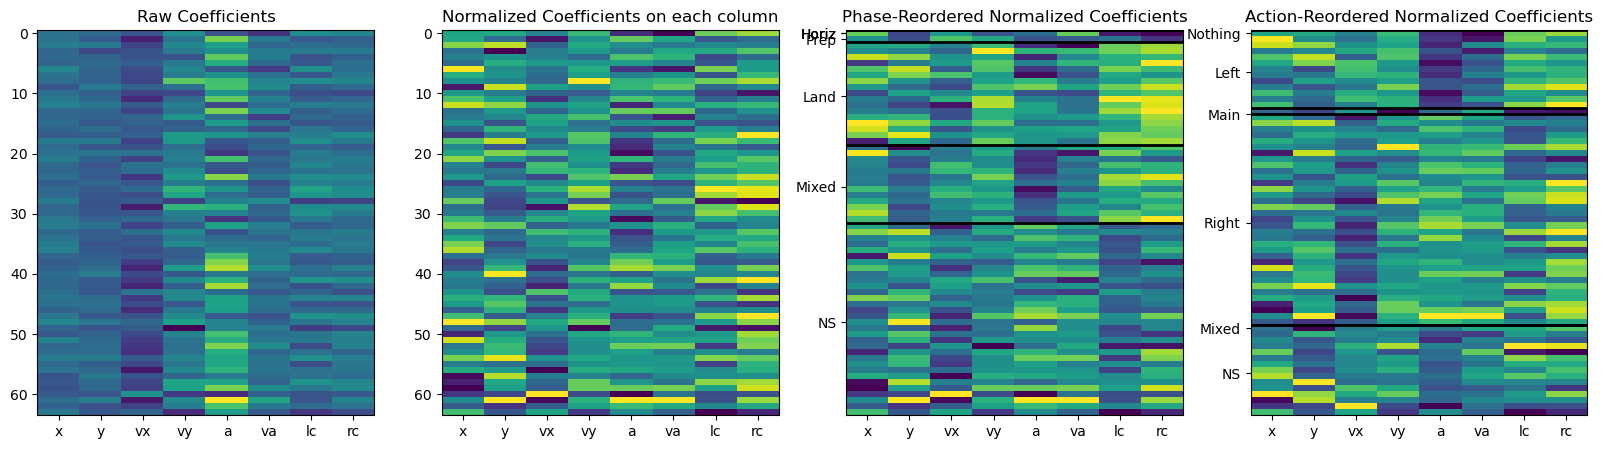

In [287]:
from sklearn.linear_model import LinearRegression
from matplotlib import pyplot as plt
reg = LinearRegression().fit(buffer_state, buffer_hidden)
print('R^2:', reg.score(buffer_state, buffer_hidden))
print('Coefficients:', reg.coef_.shape)
normalized_coefficients = (reg.coef_ - np.min(reg.coef_, axis=0))/(np.max(reg.coef_, axis=0) - np.min(reg.coef_, axis=0)+1e-10)
print(phase_perm.shape)
phase_reorder_coefficients = normalized_coefficients[phase_perm]
# print('Intercept:', reg.intercept_)
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
fig, ax = plt.subplots(1,4,figsize=(20,5))
ax[0].imshow(reg.coef_, aspect='auto')
ax[0].set_title('Raw Coefficients')
ax[0].set_xticks(np.arange(len(tick_names)))
ax[0].set_xticklabels(tick_names)
ax[1].imshow(normalized_coefficients, aspect='auto')
ax[1].set_title('Normalized Coefficients on each column')
ax[1].set_xticks(np.arange(len(tick_names)))
ax[1].set_xticklabels(tick_names)
ax[2].imshow(phase_reorder_coefficients, aspect='auto')
ax[2].set_title('Phase-Reordered Normalized Coefficients')
ax[2].set_xticks(np.arange(len(tick_names)))
ax[2].set_xticklabels(tick_names)
phase_group_sizes = np.array([len(g) for g in phase_neurons] + [len(mixed_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(phase_group_sizes)

for b in phase_boundaries[:-1]:
    ax[2].axhline(b - 0.5, color='k', linewidth=2)

centers = phase_boundaries - phase_group_sizes / 2

phase_names = ['Free', 'Brake', 'Horiz', 'Prep', 'Land']
ytick_labels = phase_names + ['Mixed', 'NS']
ax[2].set_yticks(centers)
ax[2].set_yticklabels(ytick_labels)

action_reorder_coefficients = normalized_coefficients[action_perm]
ax[3].imshow(action_reorder_coefficients, aspect='auto')
ax[3].set_title('Action-Reordered Normalized Coefficients')
ax[3].set_xticks(np.arange(len(tick_names)))
ax[3].set_xticklabels(tick_names)
action_group_sizes = n_neurons
assert sum(action_group_sizes)==N
action_boundaries = np.cumsum(action_group_sizes)
for b in action_boundaries[:-1]:
    ax[3].axhline(b - 0.5, color='k', linewidth=2)
centers = action_boundaries - np.array(action_group_sizes) / 2
action_related_names = ['Nothing', 'Left', 'Main', 'Right', 'Mixed', 'NS']
ax[3].set_yticks(centers)
ax[3].set_yticklabels(action_related_names)
plt.show()

Abnormal Detection


In [288]:
from rl.phase_detect import event_selectivity
# Assume:
# buffer_state: [L, state_dim], state[:,4] = angle
# buffer_action: [L, 1] or [L,]
# buffer_hidden: [L, hidden_size]

angle = buffer_state[:, 4]
action = buffer_action.reshape(-1).astype(int)

tilt_thr = 0.2

left_over_tilt = angle > tilt_thr
right_engine = (action == 3)

# (A) Purely state-based "left abnormal" event:
left_abnormal = left_over_tilt

# (B) "left abnormal + corrective action" event:
left_abnormal_corr = left_over_tilt & right_engine

# Use (B) if you want neurons that are specifically active when the network is correcting.
event_mask_left = left_abnormal_corr
print(left_abnormal.sum(), event_mask_left.sum())
if event_mask_left.sum() < 50:  # fallback if too few samples
    print("Too few left_abnormal_corr events, falling back to state-only left_abnormal.")
    event_mask_left = left_abnormal

left_sel = event_selectivity(buffer_hidden, event_mask_left)  # [hidden_size]


517 216


In [289]:
right_over_tilt = angle < -tilt_thr
right_abnormal = right_over_tilt
left_engine = (action == 1)

right_abnormal_corr = right_over_tilt & left_engine
event_mask_right = right_abnormal_corr
print(right_over_tilt.sum(), event_mask_right.sum())
if event_mask_right.sum() < 50:
    print("Too few right_abnormal_corr events, fallback to state-only.")
    event_mask_right = right_abnormal

right_sel = event_selectivity(buffer_hidden, event_mask_right)

546 254


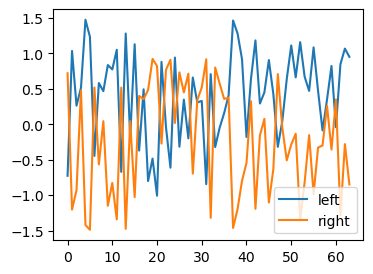

left threshold: 0.29950609956412866
Top left-over-tilt-correction neurons: [ 0  1  3  4  5  6  7  8  9 10 11 12 13 15 16 17 18 19 20 21 23 24 25 26
 28 29 30 31 32 33 36 37 38 39 41 42 44 45 46 47 49 50 51 52 53 54 55 56
 58 59 61 62 63] [-0.72677898  1.03562785  0.51564461  1.47577471  1.23550683 -0.44605873
  0.58276996  0.46769085  0.8363299   0.77480469  1.05260331 -0.67139906
  1.28207338  1.13001138 -0.37096203  0.49389872 -0.80139584 -0.48396157
 -1.00848324  0.88106366 -0.61249955  0.94291082 -0.31665671  0.34867595
  0.66079643  0.30894405  0.33006034 -0.84515612  0.70850185 -0.32075129
  0.40696578  1.4656495   1.28347906  0.91873796  0.63997692  1.18464875
  0.45085513  0.90703558  0.42772878 -0.3180808   0.63909024  1.11314026
  0.66267175  1.15975697  0.67069089  0.47156319  1.08590414  0.47158287
  0.34887508  0.8235756   0.84928913  1.06888362  0.95224972]
right threshold: 0.3285245204173528
Top right-over-tilt-correction neurons: [ 0  1  2  3  4  5  6  7  9 10 11 12 13 

In [294]:
fig, ax = plt.subplots(1,1,figsize=(4,3))
ax.plot(left_sel, label='left')
ax.plot(right_sel, label='right')
plt.legend()
plt.show()

H = buffer_hidden.shape[1]
k = 15

# Sort by absolute selectivity
# idx_sorted = np.argsort(-np.abs(left_sel))
# top_left_neurons = idx_sorted[:k]
left_threshold = np.std(np.abs(left_sel))*0.8
print('left threshold:', left_threshold)
top_left_neurons = np.where(np.abs(left_sel)>left_threshold)[0]
exc_inh_mask_left = np.where(left_sel[top_left_neurons] > 0, 1, 0)

print("Top left-over-tilt-correction neurons:", top_left_neurons, left_sel[top_left_neurons])
# idx_sorted = np.argsort(-np.abs(right_sel))
# top_right_neurons = idx_sorted[:k]
right_threshold = np.std(np.abs(right_sel))*0.8
print('right threshold:', right_threshold)
top_right_neurons = np.where(np.abs(right_sel)>right_threshold)[0]
exc_inh_mask_right = np.where(right_sel[top_right_neurons] > 0, 1, 0)
print("Top right-over-tilt-correction neurons:", top_right_neurons, right_sel[top_right_neurons])
non_selective_neurons = np.setdiff1d(np.arange(H), np.concatenate([top_left_neurons, top_right_neurons]))
print(non_selective_neurons.shape)

(53, 51) (53, 51) (53,)
Used 78 events


/tmp/ipykernel_2571/2381180494.py:66: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


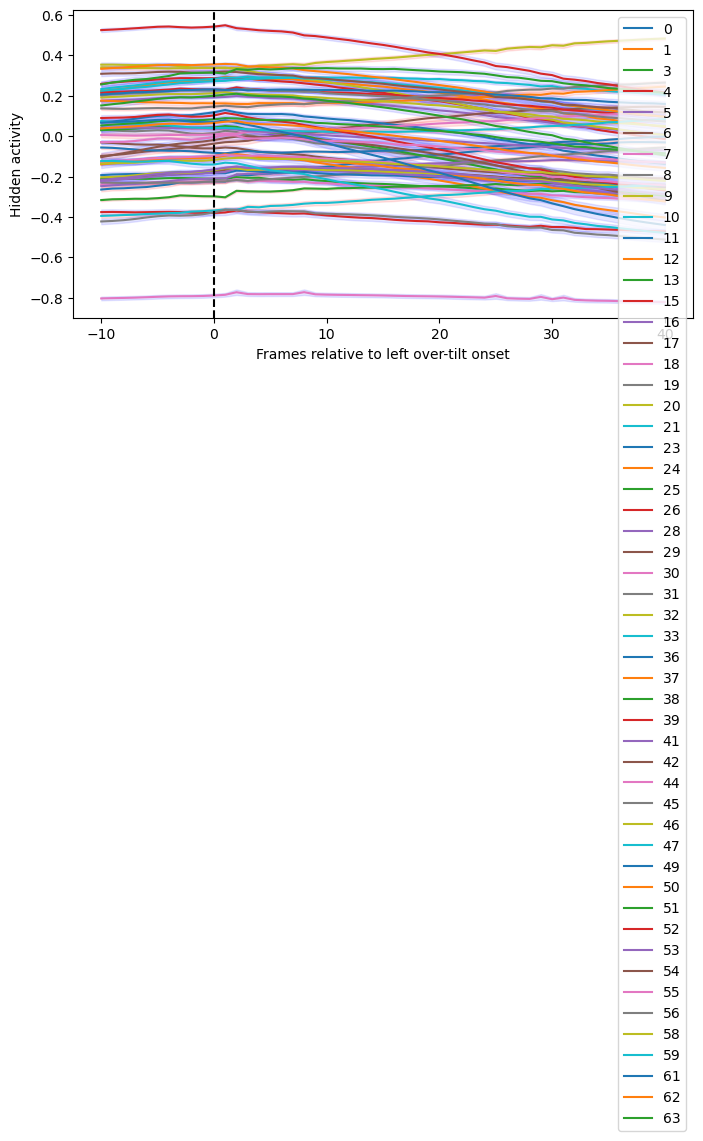

(53, 51) (53, 51) (50,)
Used 69 events


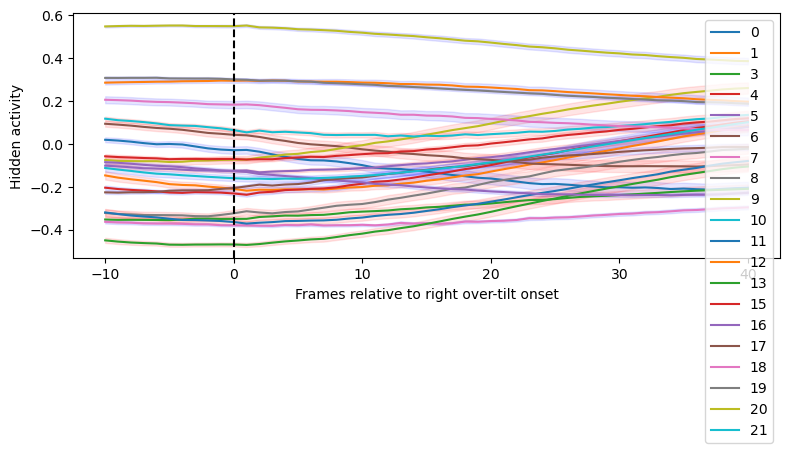

In [ ]:
def find_event_onsets(mask: np.ndarray, min_gap: int = 5) -> np.ndarray:
    """
    Find onset indices where mask goes from False -> True.
    min_gap: require at least this many frames of False before a new onset.
    """
    mask = mask.astype(bool)
    onsets = []
    prev_on = -min_gap
    for t in range(1, len(mask)):
        if mask[t] and not mask[t-1] and (t - prev_on) >= min_gap:
            onsets.append(t)
            prev_on = t
    return np.array(onsets, dtype=int)

def peri_event_hidden(buffer_hidden: np.ndarray,
                      event_mask: np.ndarray,
                      center_neurons: np.ndarray,
                      pre: int = 10,
                      post: int = 20):
    """
    Compute peri-event average activity for selected neurons.
    Returns [len(center_neurons), pre+post+1]
    """
    assert event_mask.shape[0] == buffer_hidden.shape[0]
    onsets = find_event_onsets(event_mask)
    H = len(center_neurons)
    T = pre + post + 1
    acc = []
    count = 0

    for t0 in onsets:
        if t0 - pre < 0 or t0 + post >= buffer_hidden.shape[0]:
            continue
        seg = buffer_hidden[t0-pre:t0+post+1, center_neurons]  # [T, H]
        acc.append(seg.T)
        count += 1
    acc_array = np.array(acc)
    acc_mean = acc_array.mean(0)
    acc_std = acc_array.std(0)/np.sqrt(acc_array.shape[0]-1)
    return acc_mean, acc_std, count

# random_neurons = np.random.choice(np.setdiff1d(np.arange(H), top_left_neurons), size=12)
random_neurons = non_selective_neurons
neurons_to_plot = top_left_neurons
exc_inh_mask_to_plot = exc_inh_mask_left
abnormal_to_plot = event_mask_left
avg_left, std_left, n_events = peri_event_hidden(
    buffer_hidden,
    abnormal_to_plot,          # or left_abnormal_corr
    neurons_to_plot,
    pre=10,
    post=40)
print(avg_left.shape, std_left.shape, exc_inh_mask_to_plot.shape)
exc_inh_colors = ['red', 'blue']
print("Used", n_events, "events")
import matplotlib.pyplot as plt
time = np.arange(-10, 41)
plt.figure(figsize=(8,4))
for i, n in enumerate(neurons_to_plot):
    plt.plot(time, avg_left[i], label=f'{n}')
    plt.fill_between(time, avg_left[i] - std_left[i], avg_left[i] + std_left[i], alpha=0.1, color=exc_inh_colors[exc_inh_mask_to_plot[i]])
plt.axvline(0, color='k', linestyle='--')
plt.xlabel('Frames relative to left over-tilt onset')
plt.ylabel('Hidden activity')
plt.legend()
plt.tight_layout()
plt.show()



random_neurons = np.random.choice(np.setdiff1d(np.arange(H), top_right_neurons), size=12)
random_neurons = non_selective_neurons
neurons_to_plot = top_right_neurons
exc_inh_mask_to_plot = exc_inh_mask_right
abnormal_to_plot = event_mask_right
avg_left, std_left, n_events = peri_event_hidden(
    buffer_hidden,
    abnormal_to_plot,          # or left_abnormal_corr
    neurons_to_plot,
    pre=10,
    post=40)
print(avg_left.shape, std_left.shape, exc_inh_mask_to_plot.shape)
exc_inh_colors = ['red', 'blue']
print("Used", n_events, "events")
time = np.arange(-10, 41)
plt.figure(figsize=(8,4))
for i, n in enumerate(neurons_to_plot[:20]):
    plt.plot(time, avg_left[i], label=f'{n}')
    plt.fill_between(time, avg_left[i] - std_left[i], avg_left[i] + std_left[i], alpha=0.1, color=exc_inh_colors[exc_inh_mask_to_plot[i]])
plt.axvline(0, color='k', linestyle='--')
plt.xlabel('Frames relative to right over-tilt onset')
plt.ylabel('Hidden activity')
plt.legend()
plt.tight_layout()
plt.show()

See how these correction neurons connect to left engine and right engine
